# Reliability diagrams on the test set (mask models)

Calibration of the final CT + mask models on the 290 test nodules: for each confidence level, how often the
predicted rating matched the median rating. One diagram per model:

- **Single split, models A and B:** the test predictions of seeds 1-3 **pooled** (3 × 290 = 870 predictions),
  so the bins hold more nodules than one run would (`runs/cls_no_fold_mask`)
- **Folds ensembles, models A and B:** the 4 fold models' probabilities averaged per nodule, as in
  `score_test_fold.py` (`runs/cls_mask`)

Drawn with `_reliability_png` from `plots.py`, the same function as the validation diagrams.
**Reading them:** bars above the dashed line = underconfident (right more often than it claims),
below = overconfident. The number on each bar is how many predictions are in that bin; pale bars have fewer than 10.

The ECE in each title is the ECE of that pooled or ensemble prediction set. For single split it is therefore
not the same as the mean ECE over seeds in `summary.csv`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
from IPython.display import Image, display

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py
import metrics as M
from plots import _reliability_png

SINGLE_DIR = PROJECT / "runs" / "cls_no_fold_mask"
FOLDS_DIR = PROJECT / "runs" / "cls_mask"
SINGLE_OUT = PROJECT / "results" / "test_no_fold_mask"     # the diagrams are saved next to the other test results
FOLDS_OUT = PROJECT / "results" / "test_fold_mask"
SEEDS = [1, 2, 3]
FOLDS = [1, 2, 3, 4]
P_COLS = [f"p{k}" for k in range(1, 6)]

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

290 test nodules


## Combine each model's runs into one prediction set

In [2]:
def probs_of(run_dir):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(run_dir / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

diagrams = []     # (title, probs, true ratings, output file)
for kind, model in (("hard", "A"), ("soft", "B")):
    # single split: pool the 3 seeds, so each test nodule appears 3 times (once per seed)
    pooled = np.concatenate([probs_of(SINGLE_DIR / f"{kind}_seed{s}") for s in SEEDS])
    diagrams.append((f"Single split, model {model} (3 seeds pooled)", pooled, np.tile(hard, len(SEEDS)),
                     SINGLE_OUT / f"reliability_{kind}_pooled.png"))
    # folds: the ensemble, the 4 fold models' probabilities averaged per nodule
    ensemble = np.mean([probs_of(FOLDS_DIR / f"{kind}_fold{k}") for k in FOLDS], axis=0)
    diagrams.append((f"Folds ensemble, model {model}", ensemble, hard,
                     FOLDS_OUT / f"reliability_{kind}_ensemble.png"))

## Check: the ensembles' ECE matches per_run.csv from the scoring script

In [3]:
per_run = pd.read_csv(FOLDS_OUT / "per_run.csv").set_index("run")
for title, probs, h, _ in diagrams:
    if "ensemble" in title:
        kind = "hard" if "model A" in title else "soft"
        print(f"{title}: ECE here {M.ece(probs, h):.4f}, in per_run.csv {per_run.loc[f'{kind}_ensemble', 'ece']:.4f}")

Folds ensemble, model A: ECE here 0.0318, in per_run.csv 0.0318
Folds ensemble, model B: ECE here 0.1423, in per_run.csv 0.1423


## Draw and show the diagrams

results/test_no_fold_mask/reliability_hard_pooled.png


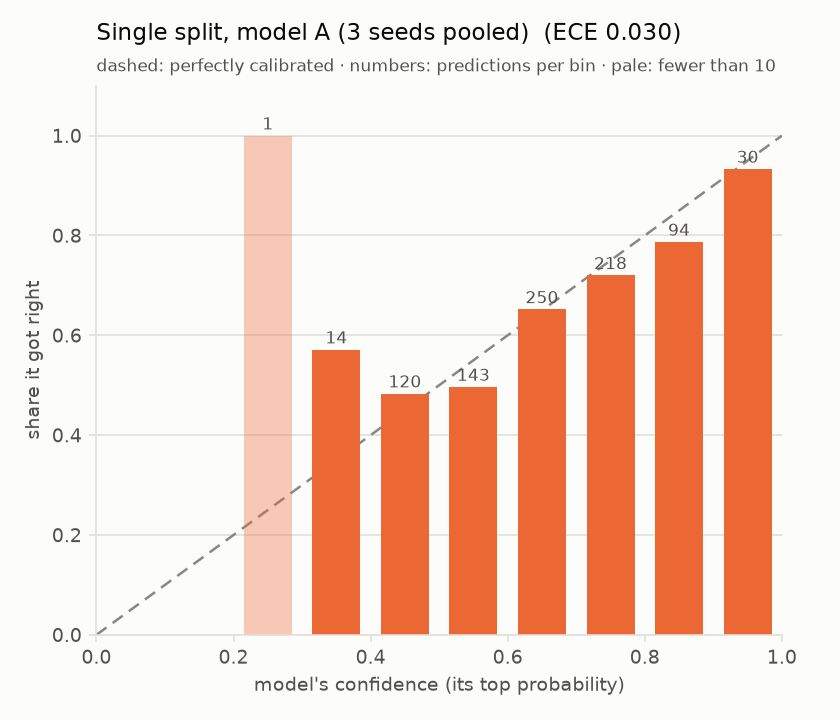

results/test_fold_mask/reliability_hard_ensemble.png


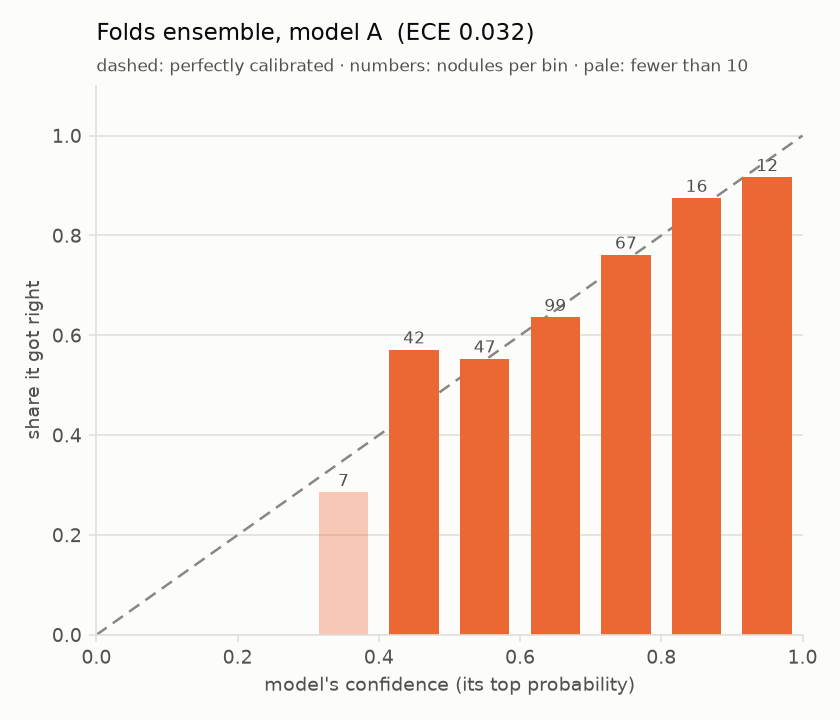

results/test_no_fold_mask/reliability_soft_pooled.png


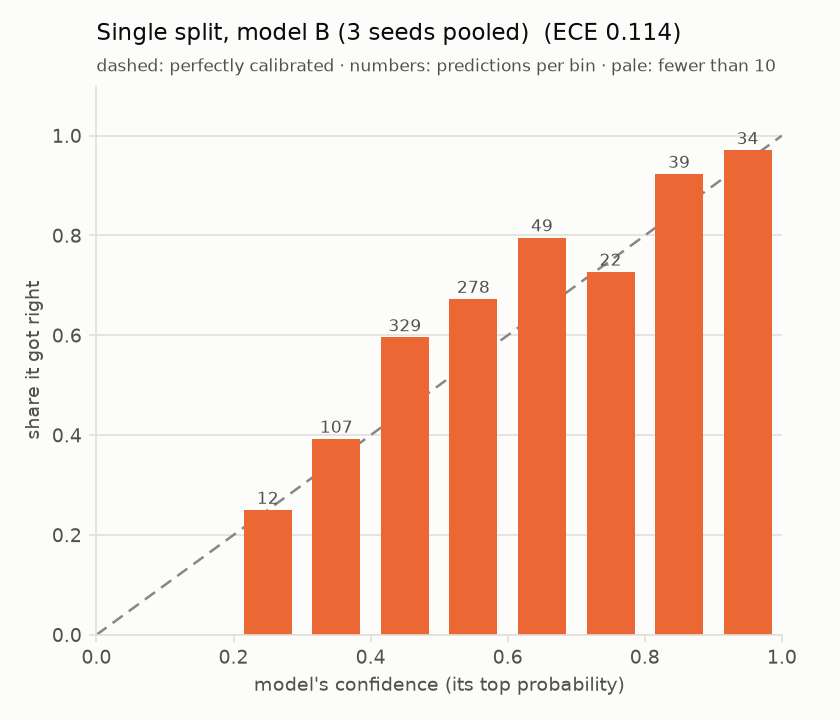

results/test_fold_mask/reliability_soft_ensemble.png


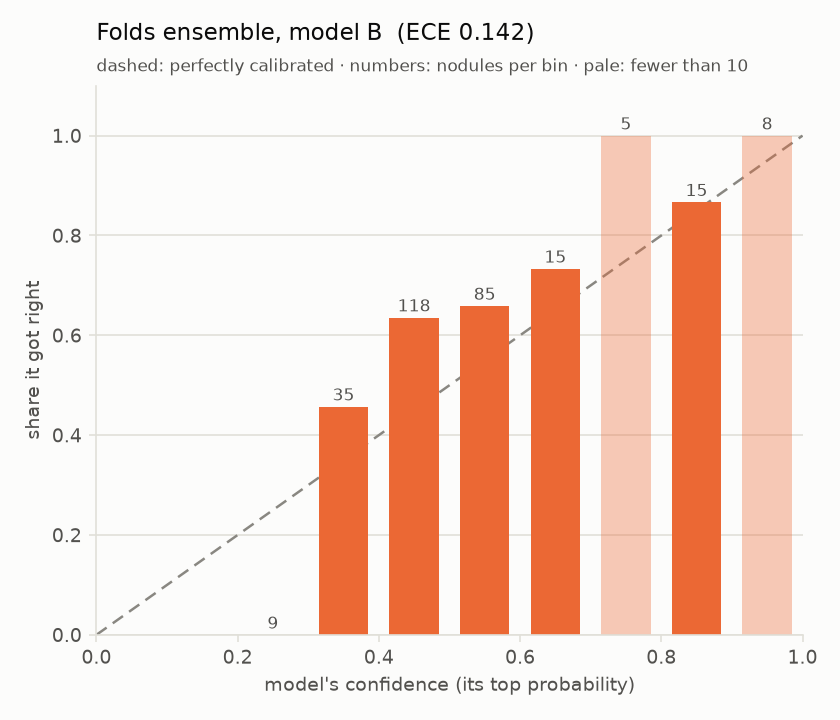

In [4]:
matplotlib.use("Agg") # _reliability_png saves to a file; the saved file is shown below
for title, probs, h, path in diagrams:
    # pooled seeds: each test nodule appears 3 times, so the bar numbers count predictions
    counted = "predictions" if "pooled" in title else "nodules"
    _reliability_png(probs, h, M.ece(probs, h), title, path, counted=counted)
    print(path.relative_to(PROJECT))
    display(Image(filename=str(path), width=480))